In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

60,000 images in the training (42000,785)and testing (28000,784), with each image represented as 28 x 28 pixels

In [ ]:
data = pd.read_csv("train.csv") # Remove the leading space from the filename
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


<ipython-input-62-2751f91592a2>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=data['label'], palette="icefire")  # Replace 'label' with the actual column name


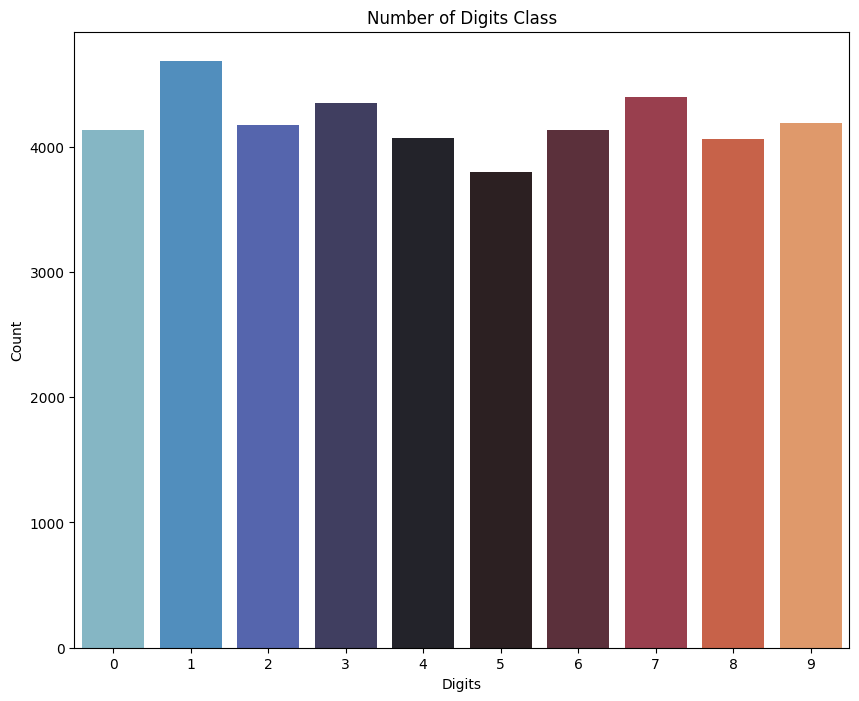

In [ ]:
plt.figure(figsize=(10, 8))
sns.countplot(x=data['label'], palette="icefire")  # Replace 'label' with the actual column name
plt.title("Number of Digits Class")
plt.xlabel("Digits")
plt.ylabel("Count")
plt.show()



Divide data into test(1000 examples) and train


In [ ]:
data = np.array(data)
m, n = data.shape
np.random.shuffle(data)

data_dev = data[0:1000].T
Y_dev = data_dev[0]
X_dev = data_dev[1:n]
X_dev = X_dev / 255.

data_train = data[1000:m].T
Y_train = data_train[0]
X_train = data_train[1:n]
X_train = X_train / 255.
_,m_train = X_train.shape

In [ ]:
Y_train


array([2, 9, 5, ..., 9, 4, 0])

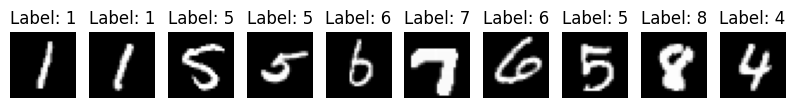

In [ ]:
def plot_sample_images(X, Y, num_samples=10):
    plt.figure(figsize=(10, 2))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        image = X[:, i].reshape(28, 28) * 255  # Reshape and denormalize
        plt.imshow(image, cmap='gray')
        plt.title(f"Label: {Y[i]}")
        plt.axis('off')
    plt.show()

# Plot 10 random samples
plot_sample_images(X_train, Y_train)


# Xavier Initialization for Parameters

Xavier initialization sets the weights using a normal distribution scaled by the number of input and output units of the layer to maintain consistent variance of activations across layers.

## **Formulas for Parameter Initialization**

### **1. Hidden Layer Weights and Biases**
- Weights (\( W_1 \)):
$$ W_1 \sim \mathcal{N}\left(0, \sqrt{\frac{2}{n_{\text{in}} + n_{\text{out}}}}\right), \text{ where } n_{\text{in}} = 784, \, n_{\text{out}} = 10 $$
- Biases (\( b_1 \)):
$$ b_1 = 0, \text{ size: } (10, 1) $$

### **2. Output Layer Weights and Biases**
- Weights (\( W_2 \)):
$$ W_2 \sim \mathcal{N}\left(0, \sqrt{\frac{2}{n_{\text{in}} + n_{\text{out}}}}\right), \text{ where } n_{\text{in}} = 10, \, n_{\text{out}} = 10 $$
- Biases (\( b_2 \)):
$$ b_2 = 0, \text{ size: } (10, 1) $$

## **General Xavier Initialization Formula**
For weights in layer \( l \):
$$ W^{(l)} \sim \mathcal{N}\left(0, \sqrt{\frac{2}{n_{\text{in}}^{(l)} + n_{\text{out}}^{(l)}}}\right) $$



In [ ]:
def init_params():
    # Xavier Initialization for W1
    W1 = np.random.normal(size=(10, 784)) * np.sqrt(2 / (784 + 10))
    b1 = np.zeros((10, 1))  # Biases are typically initialized to zero

    # Xavier Initialization for W2
    W2 = np.random.normal(size=(10, 10)) * np.sqrt(2 / (10 + 10))
    b2 = np.zeros((10, 1))  # Biases are typically initialized to zero

    return W1, b1, W2, b2




def ReLU(Z):
    return np.maximum(Z, 0)

def softmax(Z):
    A = np.exp(Z) / sum(np.exp(Z))
    return A

def forward_prop(W1, b1, W2, b2, X):
    Z1 = W1.dot(X) + b1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2

def ReLU_deriv(Z):
    return Z > 0

def one_hot(Y):
    # Convert Y to integers to ensure correct array shape
    Y = Y.astype(int)
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y

def backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y, lambd):
    m = X.shape[1]
    one_hot_Y = one_hot(Y)
    dZ2 = A2 - one_hot_Y
    dW2 = 1 / m * dZ2.dot(A1.T) + (lambd / m) * W2
    db2 = 1 / m * np.sum(dZ2, axis=1, keepdims=True)
    dZ1 = W2.T.dot(dZ2) * ReLU_deriv(Z1)
    dW1 = 1 / m * dZ1.dot(X.T) + (lambd / m) * W1
    db1 = 1 / m * np.sum(dZ1, axis=1, keepdims=True)
    return dW1, db1, dW2, db2


def update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha):
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    return W1, b1, W2, b2



---

### Forward Propagation Equations:
$$
Z^{[1]} = W^{[1]} X + b^{[1]}
$$
$$
A^{[1]} = g_{\text{ReLU}}(Z^{[1]})
$$
$$
Z^{[2]} = W^{[2]} A^{[1]} + b^{[2]}
$$
$$
A^{[2]} = g_{\text{softmax}}(Z^{[2]})
$$

---

### Backward Propagation Equations:
$$
dZ^{[2]} = A^{[2]} - Y
$$
$$
dW^{[2]} = \frac{1}{m} dZ^{[2]} A^{[1]^T}
$$
$$
dB^{[2]} = \frac{1}{m} \sum dZ^{[2]}
$$
$$
dZ^{[1]} = W^{[2]^T} dZ^{[2]} \cdot g'_{\text{ReLU}}(Z^{[1]})
$$
$$
dW^{[1]} = \frac{1}{m} dZ^{[1]} A^{[0]^T}
$$
$$
dB^{[1]} = \frac{1}{m} \sum dZ^{[1]}
$$

---

### Parameter Updates:
$$
W^{[2]} := W^{[2]} - \alpha dW^{[2]}
$$
$$
b^{[2]} := b^{[2]} - \alpha dB^{[2]}
$$
$$
W^{[1]} := W^{[1]} - \alpha dW^{[1]}
$$
$$
b^{[1]} := b^{[1]} - \alpha dB^{[1]}
$$



---



In [ ]:




def ReLU(Z):
    return np.maximum(Z, 0)

def softmax(Z):
    A = np.exp(Z) / sum(np.exp(Z))
    return A

def forward_prop(W1, b1, W2, b2, X):
    Z1 = W1.dot(X) + b1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2

def ReLU_deriv(Z):
    return Z > 0

def one_hot(Y):
    # Convert Y to integers to ensure correct array shape
    Y = Y.astype(int)
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y

def backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y, lambd):
    m = X.shape[1]
    one_hot_Y = one_hot(Y)
    dZ2 = A2 - one_hot_Y
    dW2 = 1 / m * dZ2.dot(A1.T) + (lambd / m) * W2
    db2 = 1 / m * np.sum(dZ2, axis=1, keepdims=True)
    dZ1 = W2.T.dot(dZ2) * ReLU_deriv(Z1)
    dW1 = 1 / m * dZ1.dot(X.T) + (lambd / m) * W1
    db1 = 1 / m * np.sum(dZ1, axis=1, keepdims=True)
    return dW1, db1, dW2, db2


def update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha):
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    return W1, b1, W2, b2



---

### **Total Loss Formula**
$$
\mathcal{L} = -\frac{1}{m} \sum_{i=1}^{m} \log \left( A2_{y_i, i} \right) + \frac{\lambda}{2m} \left( \sum_{j,k} W1_{j,k}^2 + \sum_{j,k} W2_{j,k}^2 \right)
$$

---

### **Components Explained**

1. **Cross-Entropy Loss (Data Loss):**
   $$
   \text{Data Loss} = -\frac{1}{m} \sum_{i=1}^{m} \log \left( A2_{y_i, i} \right)
   $$
   -

2. **L2 Regularization Loss:**
   $$
   \text{Regularization Loss} = \frac{\lambda}{2m} \left( \sum_{j,k} W1_{j,k}^2 + \sum_{j,k} W2_{j,k}^2 \right)
   $$

3. **Total Loss:**
   $$
   \mathcal{L} = \text{Data Loss} + \text{Regularization Loss}
   $$

---



In [ ]:
def compute_loss(A2, Y, W1, W2, lambd):
    m = Y.size
    logprobs = -np.log(A2[Y, range(m)])
    data_loss = np.sum(logprobs) / m
    # Add L2 regularization term
    reg_loss = (lambd / (2 * m)) * (np.sum(np.square(W1)) + np.sum(np.square(W2)))
    return data_loss + reg_loss

In [ ]:
def get_predictions(A2):
    return np.argmax(A2, 0)

def get_accuracy(predictions, Y):
    print(predictions, Y)
    return np.sum(predictions == Y) / Y.size

# Gradient Descent Equations

## **1. Forward Propagation Equations**
- **Input to hidden layer**:
$$ Z_1 = W_1 \cdot X + b_1 $$
- **Activation of hidden layer**:
$$ A_1 = g(Z_1) $$
- **Input to output layer**:
$$ Z_2 = W_2 \cdot A_1 + b_2 $$
- **Activation of output layer (e.g., softmax)**:
$$ A_2 = \text{softmax}(Z_2) $$

---

## **2. Loss Function**
- **Cross-Entropy with L2 Regularization**:
$$
\mathcal{L} = -\frac{1}{m} \sum_{i=1}^{m} \log(A_{2_{y_i, i}}) + \frac{\lambda}{2m} \left( \sum W_1^2 + \sum W_2^2 \right)
$$

---

## **3. Backward Propagation Equations**
- **Output layer error**:
$$ \delta_2 = A_2 - Y $$
- **Gradients for \( W_2 \)**:
$$ \frac{\partial \mathcal{L}}{\partial W_2} = \frac{1}{m} \delta_2 \cdot A_1^T + \frac{\lambda}{m} W_2 $$
- **Gradients for \( b_2 \)**:
$$ \frac{\partial \mathcal{L}}{\partial b_2} = \frac{1}{m} \sum \delta_2 $$
- **Hidden layer error**:
$$ \delta_1 = (W_2^T \cdot \delta_2) \circ g'(Z_1) $$
- **Gradients for \( W_1 \)**:
$$ \frac{\partial \mathcal{L}}{\partial W_1} = \frac{1}{m} \delta_1 \cdot X^T + \frac{\lambda}{m} W_1 $$
- **Gradients for \( b_1 \)**:
$$ \frac{\partial \mathcal{L}}{\partial b_1} = \frac{1}{m} \sum \delta_1 $$

---

## **4. Parameter Updates**
- **Update rules for weights and biases**:
$$ W_1^{(t+1)} = W_1^{(t)} - \alpha \cdot \frac{\partial \mathcal{L}}{\partial W_1} $$
$$ b_1^{(t+1)} = b_1^{(t)} - \alpha \cdot \frac{\partial \mathcal{L}}{\partial b_1} $$
$$ W_2^{(t+1)} = W_2^{(t)} - \alpha \cdot \frac{\partial \mathcal{L}}{\partial W_2} $$
$$ b_2^{(t+1)} = b_2^{(t)} - \alpha \cdot \frac{\partial \mathcal{L}}{\partial b_2} $$


In [ ]:
def gradient_descent(X, Y, alpha, iterations, lambd):
    W1, b1, W2, b2 = init_params()
    losses = []
    accuracies = []
    iteration_steps = []

    for i in range(iterations):
        # Forward propagation
        Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X)

        # Backward propagation
        dW1, db1, dW2, db2 = backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y, lambd)

        # Update parameters
        W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha)

        # Compute loss and accuracy every 10 iterations
        if i % 10 == 0:
            loss = compute_loss(A2, Y, W1, W2, lambd)
            predictions = get_predictions(A2)
            accuracy = get_accuracy(predictions, Y)

            # Store metrics
            losses.append(loss)
            accuracies.append(accuracy)
            iteration_steps.append(i)

            print(f"Iteration: {i}, Loss: {loss}, Accuracy: {accuracy}")

    # Plot loss and accuracy
    plt.figure(figsize=(12, 6))

    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(iteration_steps, losses, label="Loss", color='blue')
    plt.title("Loss vs Iterations")
    plt.xlabel("Iterations")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()

    # Accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(iteration_steps, accuracies, label="Accuracy", color='green')
    plt.title("Accuracy vs Iterations")
    plt.xlabel("Iterations")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

    return W1, b1, W2, b2




[0 0 0 ... 0 0 0] [1 1 5 ... 9 5 2]
Iteration: 0, Loss: 2.3560682858533792, Accuracy: 0.10421951219512195
[7 1 0 ... 0 6 9] [1 1 5 ... 9 5 2]
Iteration: 10, Loss: 1.881781209505028, Accuracy: 0.33902439024390246
[1 1 0 ... 0 6 6] [1 1 5 ... 9 5 2]
Iteration: 20, Loss: 1.643425370260139, Accuracy: 0.4440731707317073
[1 1 0 ... 4 6 6] [1 1 5 ... 9 5 2]
Iteration: 30, Loss: 1.4379993619336324, Accuracy: 0.5308536585365854
[1 1 8 ... 4 6 2] [1 1 5 ... 9 5 2]
Iteration: 40, Loss: 1.2512304080428112, Accuracy: 0.6068292682926829
[1 1 8 ... 4 8 2] [1 1 5 ... 9 5 2]
Iteration: 50, Loss: 1.0925123382042965, Accuracy: 0.6825853658536586
[1 1 8 ... 3 8 2] [1 1 5 ... 9 5 2]
Iteration: 60, Loss: 0.9661005376813453, Accuracy: 0.7282682926829268
[1 1 5 ... 3 8 2] [1 1 5 ... 9 5 2]
Iteration: 70, Loss: 0.8674838544631762, Accuracy: 0.7559756097560976
[1 1 5 ... 5 8 2] [1 1 5 ... 9 5 2]
Iteration: 80, Loss: 0.7903609977111319, Accuracy: 0.7783414634146342
[1 1 5 ... 5 8 2] [1 1 5 ... 9 5 2]
Iteration: 

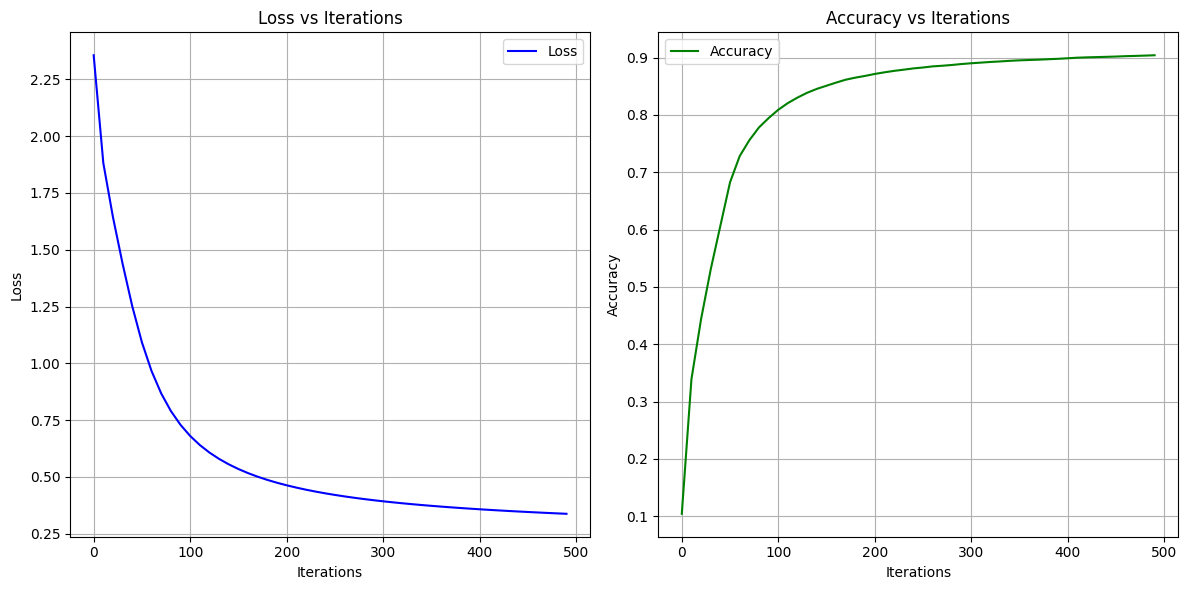

In [ ]:
W1, b1, W2, b2 = gradient_descent(X_train, Y_train, alpha=0.10, iterations=500, lambd=0.01)

In [ ]:
def make_predictions(X, W1, b1, W2, b2):
    _, _, _, A2 = forward_prop(W1, b1, W2, b2, X)
    predictions = get_predictions(A2)
    return predictions

def test_prediction(index, W1, b1, W2, b2):
    current_image = X_train[:, index, None]
    prediction = make_predictions(X_train[:, index, None], W1, b1, W2, b2)
    label = Y_train[index]
    print("Prediction: ", prediction)
    print("Label: ", label)

    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

Prediction:  [3]
Label:  7


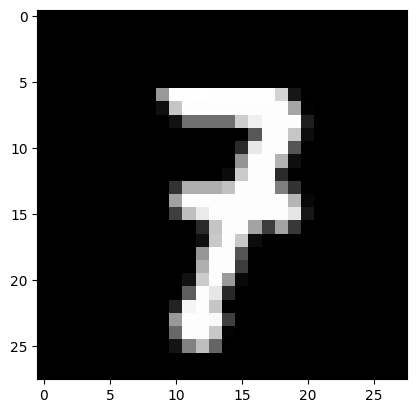

Prediction:  [7]
Label:  7


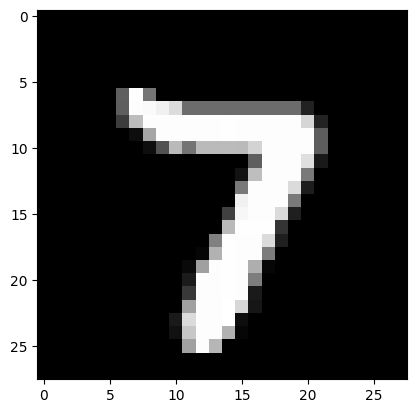

Prediction:  [1]
Label:  1


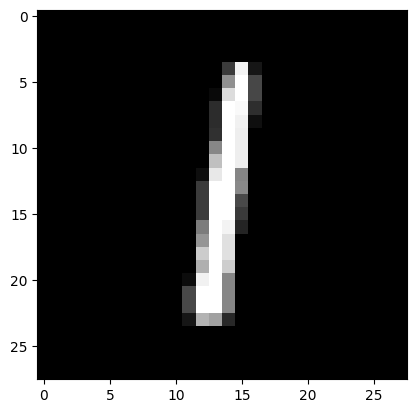

Prediction:  [7]
Label:  7


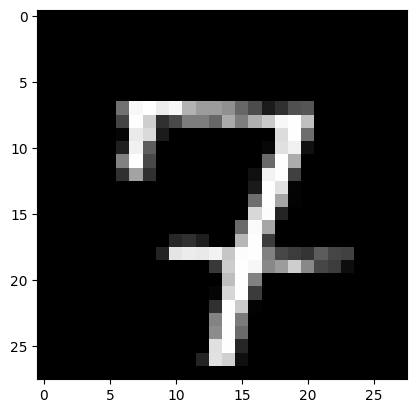

In [ ]:
test_prediction(0, W1, b1, W2, b2)
test_prediction(1, W1, b1, W2, b2)
test_prediction(2, W1, b1, W2, b2)
test_prediction(3, W1, b1, W2, b2)


In [ ]:
dev_predictions = make_predictions(X_dev, W1, b1, W2, b2)
get_accuracy(dev_predictions, Y_dev)

[2 6 8 8 4 8 6 1 5 8 5 9 4 9 5 8 5 5 3 8 7 3 6 3 0 9 1 3 1 6 4 1 3 8 2 6 5
 6 2 1 2 6 7 9 1 3 1 2 1 8 1 5 4 7 1 0 6 3 0 8 2 4 3 8 0 0 0 8 1 7 1 0 5 6
 7 3 5 5 9 3 8 2 4 6 0 6 6 6 0 9 6 9 4 0 3 1 0 4 9 8 1 8 5 4 2 0 7 0 9 3 2
 2 9 3 1 1 0 3 1 2 5 2 3 1 1 4 3 4 7 7 6 8 1 6 6 7 1 1 2 9 2 4 3 0 7 3 1 6
 8 5 0 2 3 1 2 3 5 0 7 6 9 0 2 7 4 6 5 8 8 1 1 6 5 1 3 1 4 2 4 7 5 6 9 8 8
 1 2 4 6 0 6 5 1 4 7 7 2 6 3 1 8 5 8 3 5 5 1 2 0 0 3 1 7 2 3 1 5 5 2 3 3 2
 2 0 2 2 3 6 7 0 4 4 9 4 5 0 2 5 1 6 6 5 0 1 7 6 5 0 2 3 4 1 7 5 6 7 8 7 4
 7 9 3 4 7 0 8 5 0 9 8 9 2 2 3 5 3 0 4 5 5 9 9 8 1 4 9 7 6 6 1 6 1 4 7 6 9
 8 3 6 5 2 0 7 5 1 2 7 9 3 2 5 1 2 7 6 1 6 4 9 9 7 0 7 7 0 2 2 6 8 1 2 8 1
 8 1 4 8 9 8 9 5 9 1 8 5 0 7 2 9 4 9 3 3 8 4 1 1 9 7 6 2 6 3 0 5 8 4 0 0 3
 9 4 3 5 1 9 1 0 9 7 2 6 8 3 7 8 6 4 1 9 8 9 7 3 2 9 9 0 1 0 4 4 3 5 5 3 1
 3 2 9 6 6 1 9 1 9 9 2 6 9 4 9 4 5 5 4 1 9 6 1 6 1 0 3 6 6 6 0 0 0 7 8 5 2
 8 3 7 9 0 1 4 1 2 1 6 6 0 5 4 2 2 6 4 1 3 9 4 2 4 8 9 1 9 7 9 8 2 7 8 7 8
 8 4 9 1 6 8 9 5 6 6 5 7 

0.907

In [ ]:




test_data = pd.read_csv('test.csv')


test_data = test_data.to_numpy().T / 255.

test_predictions = make_predictions(test_data, W1, b1, W2, b2)


pd.DataFrame(test_predictions).to_csv("test_predictions.csv", index=False, header=["Label"])

print("Predictions saved to test_predictions.csv")


Predictions saved to test_predictions.csv


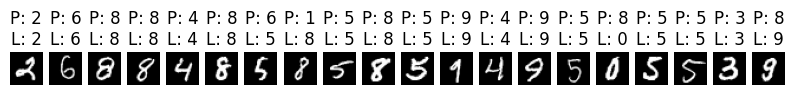

In [ ]:
def plot_test_predictions(X, Y, W1, b1, W2, b2, num_samples=10):
    predictions = make_predictions(X, W1, b1, W2, b2)
    plt.figure(figsize=(10, 2))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        image = X[:, i].reshape(28, 28) * 255  # Reshape and denormalize
        plt.imshow(image, cmap='gray')
        plt.title(f"P: {predictions[i]}\nL: {Y[i]}")
        plt.axis('off')
    plt.show()

# Plot test predictions for the first 10 samples
plot_test_predictions(X_dev, Y_dev, W1, b1, W2, b2, num_samples=20)


In [ ]:
from sklearn.model_selection import train_test_split

train_k = pd.read_csv("train.csv")
test_k= pd.read_csv("test.csv")

print(train_k.shape)
print(test_k.shape)

X_k= train_k.drop('label', axis=1)
y_k= train_k.label

X_traink, X_testk ,y_traink, y_testk = train_test_split(X_k, y_k, test_size=0.1, random_state=42)


(42000, 785)
(28000, 784)


In [ ]:
X_traink = X_traink.values.reshape(-1,28, 28)
X_testk = X_testk.values.reshape(-1, 28, 28)

X_testk = np.array(X_testk)
y_testk = np.array(y_testk)

print("Train shape:")
print(X_traink.shape)
print(y_traink.shape)

print("Test shape:")
print(X_testk.shape)
print(y_testk.shape)

Train shape:
(37800, 28, 28)
(37800,)
Test shape:
(4200, 28, 28)
(4200,)


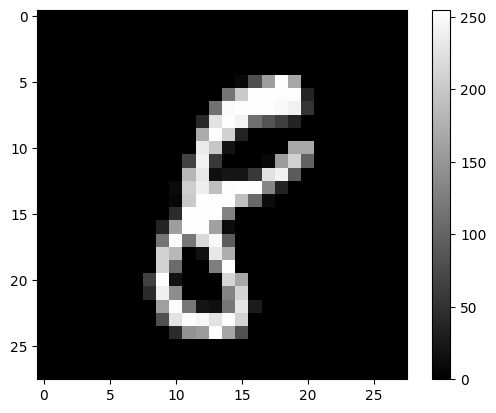

In [ ]:
plt.figure()
plt.imshow(X_traink[0])
plt.colorbar()
plt.grid(False)
plt.show()


In [ ]:
X_traink = X_traink / 255.0
X_testk = X_testk/ 255.0

In [ ]:
y_traink.iloc[1]

5

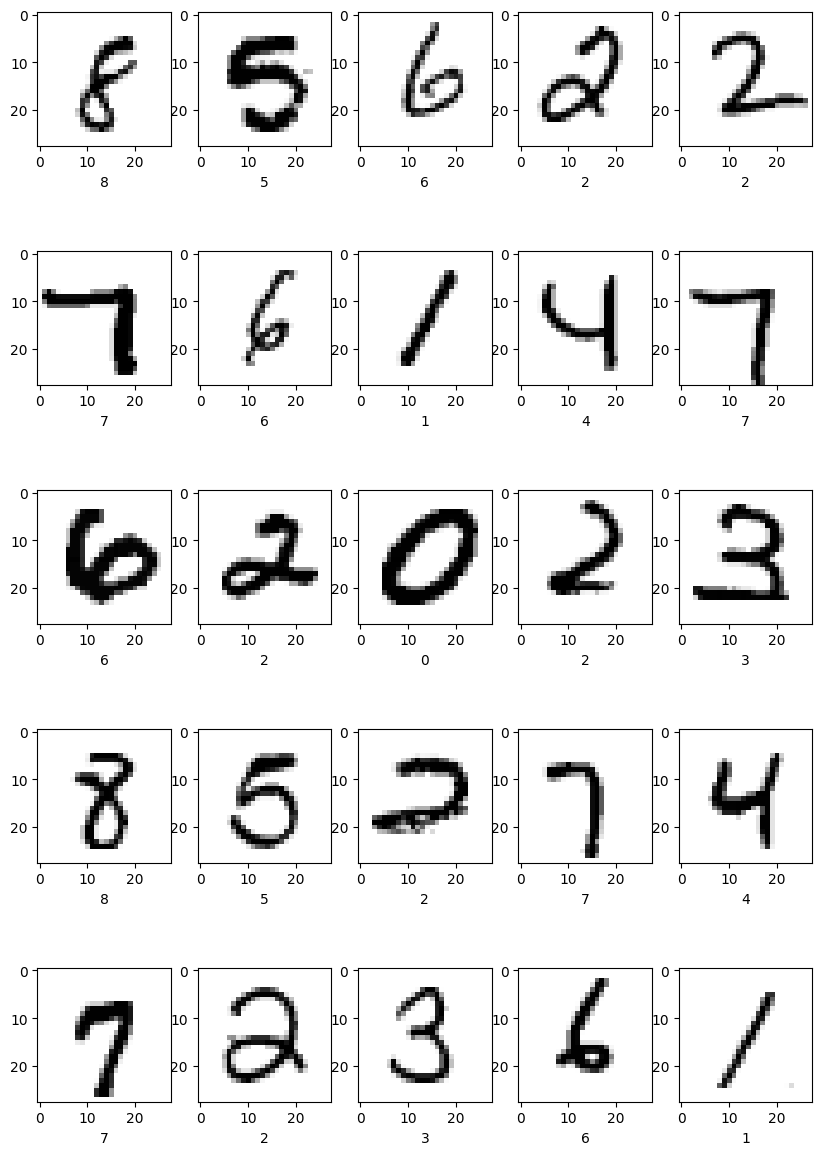

In [ ]:
plt.figure(figsize=(10, 15))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.grid(False)
    plt.imshow(X_traink[i], cmap=plt.cm.binary)
    plt.xlabel(y_traink.iloc[i])

plt.show()

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.optimizers import Adam

model = Sequential()

model.add(Input(shape=(784,)))
model.add(Dense(units=1500,activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(units=1000, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(units=500, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(units=10, activation='softmax'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 1500)                │       1,177,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1500)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1000)                │       1,501,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1000)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 500)                 │         500,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 500)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           5,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,184,010 (12.15 MB)

 Trainable params: 3,184,010 (12.15 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',
             loss='sparse_categorical_crossentropy',
             metrics=['accuracy'])

# Reshape X_traink and X_testk to flatten the images
X_traink = X_traink.reshape(X_traink.shape[0], -1)
X_testk = X_testk.reshape(X_testk.shape[0], -1)

# Now fit the model
r = model.fit(X_traink, y_traink, batch_size=256,
              epochs=20, validation_data=(X_testk, y_testk))



Epoch 1/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 23s 138ms/step - accuracy: 0.7663 - loss: 0.7243 - val_accuracy: 0.9569 - val_loss: 0.1481
Epoch 2/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 20s 137ms/step - accuracy: 0.9490 - loss: 0.1689 - val_accuracy: 0.9626 - val_loss: 0.1178
Epoch 3/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 22s 148ms/step - accuracy: 0.9628 - loss: 0.1235 - val_accuracy: 0.9648 - val_loss: 0.1127
Epoch 4/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 20s 137ms/step - accuracy: 0.9677 - loss: 0.1020 - val_accuracy: 0.9743 - val_loss: 0.0819
Epoch 5/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 21s 144ms/step - accuracy: 0.9748 - loss: 0.0780 - val_accuracy: 0.9740 - val_loss: 0.0844
Epoch 6/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 40s 138ms/step - accuracy: 0.9774 - loss: 0.0747 - val_accuracy: 0.9757 - val_loss: 0.0791
Epoch 7/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 41s 142ms/step - accuracy: 0.9798 - loss: 0.0664 - val_accuracy: 0.9757 - val_loss: 0.0829
Epoch 8/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 40s 138ms/step - accuracy: 0.9823 - loss: 0

In [ ]:


test_loss, test_acc = model.evaluate(X_testk, y_testk, verbose=2)
print(f'Test accuracy: {test_acc}\n')

132/132 - 1s - 9ms/step - accuracy: 0.9812 - loss: 0.0682
Test accuracy: 0.9811905026435852



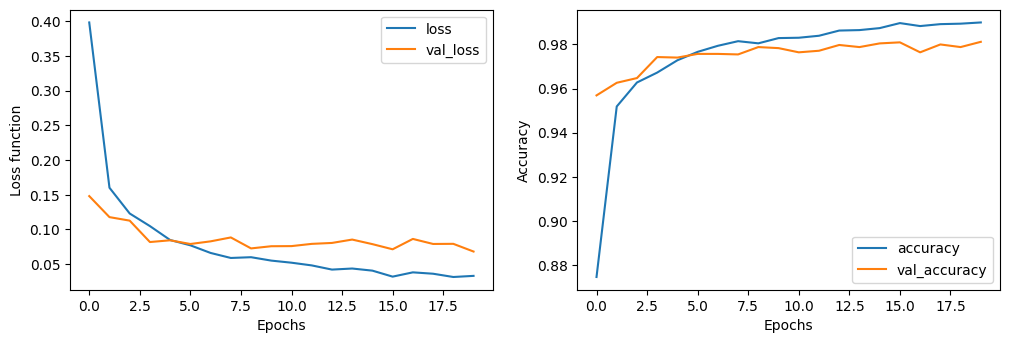

In [ ]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.plot(r.history['loss'], label='loss')
plt.plot(r.history['val_loss'], label='val_loss')
plt.xlabel("Epochs")
plt.ylabel("Loss function")
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(r.history['accuracy'], label='accuracy')
plt.plot(r.history['val_accuracy'], label='val_accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

In [ ]:
predictions = model.predict(X_testk)
predictions[0]

132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


array([3.1146030e-09, 7.9266165e-08, 3.2289909e-09, 1.0325417e-09,
       9.5740298e-11, 2.2757116e-10, 4.5450232e-10, 3.1972602e-11,
       9.9999982e-01, 2.5678476e-10], dtype=float32)

In [ ]:
np.argmax(predictions[0])

8

In [ ]:
predictions = model.predict(X_testk)

# Get the predicted classes (if it's a classification task)
predicted_classes = np.argmax(predictions, axis=1)

# Print or save the predictions as needed
print(predicted_classes)  # Print the predicted classes
# or
pd.DataFrame(predicted_classes).to_csv("test_predictions.csv", index=False, header=["Label"])  # Save to a CSV file


132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
[8 1 9 ... 7 7 5]


In [ ]:
# Assuming 'model' is your trained Keras model object
model.save('handwritten.h5')